## Cinematica inversa ridondante e ottimizzazione dei guadagni

Questa cella implementa il cuore del controllo del robot: la **cinematica
inversa differenziale** con ottimizzazione secondaria per l'evitamento dei
limiti articolari. Il problema viene risolto tramite la **pseudo-inversa dello
Jacobiano**, che fornisce la soluzione a norma minima per le velocità
articolari. Nel caso ridondante (n > m, più giunti che gradi di libertà del
task), si sfrutta il **proiettore nel nullo** dello Jacobiano per ottimizzare
contemporaneamente il funzionale w(q), spingendo i giunti verso il centro del
loro range senza alterare il moto dell'end-effector.

La traiettoria cartesiana è pianificata tramite un **polinomio cubico** che
garantisce continuità di posizione e velocità agli estremi. Il percorso è
suddiviso in due segmenti: `pi → P1` (t: 0→10s) e `P1 → P2` (t: 10→20s).

Per scegliere i guadagni ottimali `k` e `ka` si esegue una **ricerca a griglia**
su tutte le combinazioni, valutando per ognuna:
- l'**errore medio di tracking** (fedeltà alla traiettoria desiderata)
- il **valore medio di |w(q)|** (distanza dai limiti articolari)

La coppia ottimale è quella che minimizza |w| tra tutte le combinazioni il cui
errore si trova entro una soglia del 10% rispetto all'errore minimo assoluto.

In [ ]:
#Importazione delle librerie necessarie
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from mpl_toolkits.mplot3d import Axes3D  #Import per il 3D
import dill

#Caricamento delle funzioni da un file utilizzando dill
with open('funzione_ottimizzazione_3giunti.pkl', 'rb') as file:
    dw_dq_3g = dill.load(file)

with open('funzione_ottimizzazione_4giunti.pkl', 'rb') as file:
    dw_dq_4g = dill.load(file)

a = np.array([0.09, 0.005, 0.035, 0.02])
d = np.array([0.0, 0.0, 0.05, 0.0])
alpha = np.array([np.pi/2, -np.pi/2 , np.pi/2, 0.0])
q = np.array([0.0, 0.0, 0.0, 0.0])

def trasf_DH(d, a, alpha, theta):
    T = np.array([
        [np.cos(theta), -np.sin(theta)*np.cos(alpha), np.sin(theta)*np.sin(alpha), a*np.cos(theta)],
        [np.sin(theta), np.cos(theta)*np.cos(alpha), -np.cos(theta)*np.sin(alpha), a*np.sin(theta)],
        [0.0,           np.sin(alpha),               np.cos(alpha),               d],
        [0.0,           0.0,                         0.0,                         1.0]
    ])
    return T

def calcolo_posa(T):
    p = T[0:3,3]
    return p

T01 = trasf_DH(d[0], a[0], alpha[0], q[0])
T12 = trasf_DH(d[1], a[1], alpha[1], q[1]) 
T23 = trasf_DH(d[2], a[2], alpha[2], q[2])
T34 = trasf_DH(d[3], a[3], alpha[3], q[3])
T02 = np.matmul(T01,T12)
T03 = np.matmul(T02,T23)
T04 = np.matmul(T03,T34)
#posizione dell'end effector nella configurazione iniziale 
pi=T04[:3,3]

#scelgo i punti all'interno del mio spazio di lavoro casualmente
#caso iniziale senza modifica
P1 = np.array([0.100316, -0.019790, 0.055185])
P2 = np.array([0.056810, -0.047541, 0.048630])

def cartesianPlanner(pi, pf, t0, tf, t): 
    if t <= t0: #prima dell'istante iniziale, la posizione è quella iniziale e la velcotà è nulla
        pd = pi 
        pdot = np.array([0,0,0]) 
    
    elif t <= tf: 
        A = np.array([[t0**3, t0**2, t0, 1], [tf**3, tf**2, tf, 1], [3*t0**2, 2*t0, 1, 0], [3*tf**2, 2*tf, 1, 0]]) #matrice dei coefficienti del polinomio cubico

        b = np.array([[0],[np.linalg.norm(pf-pi)],[0],[0]]) #sono i vincoli 

        x = np.linalg.solve(A, b) #sono le incognite 

        s = x[0]*t**3+x[1]*t**2+x[2]*t+x[3] #calcolo ascissa curvilinea
        sdot = 3*x[0]*t**2+2*x[1]*t+x[2] #derivata dell'ascissa curvilinea
    
        pd = pi + s*(pf-pi)/np.linalg.norm(pf-pi) #posizione desiderata dell'EE
        pdot = sdot*(pf-pi)/np.linalg.norm(pf-pi) #velocità desiderata dell'EE

    elif t > tf: #dopo l'istante finale, la posizione è quella finale e la velocità è nulla
        pd = pf
        pdot = np.array([0,0,0])

    return pd, pdot


def Jacobian(q):
    T01 = trasf_DH(d[0], a[0], alpha[0], q[0])
    T12 = trasf_DH(d[1], a[1], alpha[1], q[1])
    T23 = trasf_DH(d[2], a[2], alpha[2], q[2])
    T34 = trasf_DH(d[3], a[3], alpha[3], q[3])

    T02 = np.matmul(T01, T12)
    T03 = np.matmul(T02, T23)
    T04 = np.matmul(T03, T34)

    p0 = np.zeros(3)  
    p1 = T01[:3, 3]  
    p2 = T02[:3, 3]  
    p3 = T03[:3, 3]  
    p4 = T04[:3, 3]  

    #Vettori di rotazione (asse z di ogni giunto)
    z0 = np.array([0, 0, 1])
    z1 = T01[:3, 2]
    z2 = T02[:3, 2]
    z3 = T03[:3, 2]
    #Vettori di traslazione (differenza tra la posizione dell'effettore e quella dei giunti)
    p4_p0 = p4 - p0
    p4_p1 = p4 - p1
    p4_p2 = p4 - p2
    p4_p3 = p4 - p3

    J1 = np.cross(z0, p4_p0)
    J2 = np.cross(z1, p4_p1)
    J3 = np.cross(z2, p4_p2)
    J4 = np.cross(z3, p4_p3)
    J = np.vstack((J1, J2))
    J = np.vstack((J, J3))
    J = np.vstack((J, J4))
    
    J = J.T 
    
    return J

#Cinematica inversa 
def inverseKinematics(q, xd, xdot, k, method, ka, dw_dq ):

    # Calcolo dello Jacobiano geometrico
    J = Jacobian(q)
    
    T0 = np.eye(4)
    T01 = trasf_DH(d[0], a[0], alpha[0], q[0])
    T12 = trasf_DH(d[1], a[1], alpha[1], q[1])
    T23 = trasf_DH(d[2], a[2], alpha[2], q[2])
    T34 = trasf_DH(d[3], a[3], alpha[3], q[3])                
    T02 = np.matmul(T01,T12)
    T03 = np.matmul(T02,T23)
    T04 = np.matmul(T03,T34)

    x = T04[:3,3] #posizione dell'organo terminale
    e = xd - x #errore tra posizione desiderata e posizione attuale
    err = np.linalg.norm(e) #norma dell'errore

    K = k * np.eye(3)  #matrice dei guadagni diagonale
    Err = np.matmul(K,e) #termine di correzione proporzionale
    J_ = np.linalg.pinv(J) #inversa dello Jacobiano

    if method == "inverse": #pseudo-inversa destra
        Qdot = np.matmul(J_, xdot + Err)

    elif method == "inverse_redundant": 
        P = np.eye(J.shape[1]) - np.matmul(J_, J) #proiettore nel nullo dello Jacobiano
        grad = np.array(dw_dq(*q), dtype=float).flatten()  # shape (4,)
        Qdot = np.matmul(J_, xdot + Err) + ka * np.matmul(P, grad)

    return Qdot, err #vettore delle velocità angolari e errore

t0 = 0 
tm = 10
tf = 20
dt = 0.01

pf1 = P1
pf2 = P2
time=np.arange(t0,tf,dt)
k_vector  = list(range(20, 300, 20))   
ka_vector = list(range(0, 51, 5))

In [ ]:
q0 = np.array([0,0,0,0])
Qd = np.zeros((len(time), 4)) 
Qdot = np.zeros((len(time), 4)) 
Qd[0,:] = q0 
Qdot[0,:] = np.array([0,0,0,0])  

#Inizializzazione SO
T01 = trasf_DH(d[0], a[0], alpha[0], q0[0])
T12 = trasf_DH(d[1], a[1], alpha[1], q0[1])
T23 = trasf_DH(d[2], a[2], alpha[2], q0[2])
T34 = trasf_DH(d[3], a[3], alpha[3], q0[3])
T02 = np.matmul(T01,T12)
T03 = np.matmul(T02, T23)
T04 = np.matmul(T03, T34)


Estremi = [(np.deg2rad(-129), np.deg2rad(25)),   
        (np.deg2rad(-10), np.deg2rad(165)), 
        (np.deg2rad(-86), np.deg2rad(11)),
        (np.deg2rad(0), np.deg2rad(360))] 
qm = np.array([e[0] for e in Estremi])
qM = np.array([e[1] for e in Estremi])
n = 4  #numero di giunti

#Cerco le combinazioni migiiori di k e ka
results = []
for k in k_vector:
    for ka in ka_vector:
        #inizializzo spazio operativo
        q0_func = np.array([0,0,0,0])
        Qd_func = np.zeros((len(time), 4)) 
        Qd_func[0,:] = q0_func   

        #inizializzo spazio dei giunti
        # vettore delle posizioni reali dell'EE
        p_ee_func = np.zeros((len(time),3))
        p_ee_func[0,:] = calcolo_posa(T04)

        # vettori delle pose e velcooità desiderate dell'EE
        Pd_func = np.zeros((len(time),3))
        Pd_func[0,:] = pi

        error_func = np.zeros((len(time),1))
        error_func[0] = np.linalg.norm(Pd_func[0,:]-p_ee_func[0,:])
        wf = np.zeros(len(time))

        for idx, t in enumerate(time):
            if t <= tm:
                pd_func, pdot_func = cartesianPlanner(pi, pf1, t0, tm, t)
            else:
                pd_func, pdot_func = cartesianPlanner(pf1, pf2, tm, tf, t)

            qdot_func , error_func[idx] = inverseKinematics(Qd_func[idx, :], pd_func, pdot_func, k, "inverse_redundant", ka, dw_dq_4g)
            
            # Calcolo funzionale w 
            sommatoriaf = 0
            for j in range(n):
                q_med = (qm[j] + qM[j]) / 2
                sommatoriaf += ((Qd_func[idx, j] - q_med) / (qM[j] - qm[j])) ** 2
            wf[idx] = -(0.5 / (n) * sommatoriaf) 

            if idx + 1 < len(time):
                Qd_func[idx + 1, :] = Qd_func[idx, :] + qdot_func * dt  

        # Metriche calcolate su tutta la traiettoria
        errore_rms = np.sqrt(np.mean(error_func**2))

        # Media dei valori assoluti di W(q) sulla traiettoria
        w_medio = np.mean(np.abs(wf))

        print(f"k = {k}, ka = {ka}: errore rms = {errore_rms:.6f}, |w| medio = {w_medio:.6f}")
        results.append((k, ka , errore_rms, w_medio, error_func.copy(), wf.copy())) 

# Selezione della coppia ottimale (k, ka) 
errore_minimo = min(results, key=lambda x: x[2])[2] # trovo l'errore minimo
soglia = errore_minimo * 1.2 # imposto una soglia di accettazione al 120% dell'errore minimo
candidati = [r for r in results if r[2] <= soglia] # scarto le coppie che superano la soglia
best = min(candidati, key=lambda x: x[3])  # trovo |W| minimo
k_best, ka_best = best[0], best[1] # seleziono la coppia corrispondente

print(f"\nMigliori guadagni: k = {k_best}, ka = {ka_best}")
print(f"  errore rms = {best[2]:.6f} m")
print(f"  |W| medio  = {best[3]:.6f}  (0 = centro corsa)")

k = 20, ka = 0: errore rms = 0.000000, |w| medio = 0.084669
k = 20, ka = 5: errore rms = 0.000000, |w| medio = 0.070632
k = 20, ka = 10: errore rms = 0.000000, |w| medio = 0.070359
k = 20, ka = 15: errore rms = 0.000000, |w| medio = 0.070177
k = 20, ka = 20: errore rms = 0.000001, |w| medio = 0.070055
k = 20, ka = 25: errore rms = 0.000001, |w| medio = 0.069972
k = 20, ka = 30: errore rms = 0.000001, |w| medio = 0.069914
k = 20, ka = 35: errore rms = 0.000001, |w| medio = 0.069872
k = 20, ka = 40: errore rms = 0.000001, |w| medio = 0.069840
k = 20, ka = 45: errore rms = 0.000002, |w| medio = 0.069816
k = 20, ka = 50: errore rms = 0.000002, |w| medio = 0.069797
k = 40, ka = 0: errore rms = 0.000000, |w| medio = 0.084669
k = 40, ka = 5: errore rms = 0.000000, |w| medio = 0.070632
k = 40, ka = 10: errore rms = 0.000000, |w| medio = 0.070359
k = 40, ka = 15: errore rms = 0.000000, |w| medio = 0.070177
k = 40, ka = 20: errore rms = 0.000000, |w| medio = 0.070055
k = 40, ka = 25: errore rms 

In [ ]:
q0 = np.array([0,0,0,0])
Qd_3 = np.zeros((len(time), 4)) 
Qdot_3 = np.zeros((len(time), 4)) 
Qd_3[0,:] = q0 
Qdot_3[0,:] = np.array([0,0,0,0])  

#Inizializzazione SO
T01 = trasf_DH(d[0], a[0], alpha[0], q[0])
T12 = trasf_DH(d[1], a[1], alpha[1], q[1])
T23 = trasf_DH(d[2], a[2], alpha[2], q[2])
T34 = trasf_DH(d[3], a[3], alpha[3], q[3])
T02 = np.matmul(T01,T12)
T03 = np.matmul(T02, T23)
T04 = np.matmul(T03, T34)


Estremi = [(np.deg2rad(-129), np.deg2rad(25)),   
        (np.deg2rad(-10), np.deg2rad(165)), 
        (np.deg2rad(-86), np.deg2rad(11)),
        (np.deg2rad(0), np.deg2rad(360))] 
qm = np.array([e[0] for e in Estremi])
qM = np.array([e[1] for e in Estremi])
n = 3  #numero di giunti

#Cerco le combinazioni migiiori di k e ka
results_3 = []
for k_3 in k_vector:
    for ka_3 in ka_vector:
        #inizializzo spazio operativo
        q0_func = np.array([0,0,0,0])
        Qd_func = np.zeros((len(time), 4)) 
        Qd_func[0,:] = q0_func   

        #inizializzo spazio dei giunti
        # vettore delle posizioni reali dell'EE
        p_ee_func = np.zeros((len(time),3))
        p_ee_func[0,:] = calcolo_posa(T04)

        # vettori delle pose e velcooità desiderate dell'EE
        Pd_func = np.zeros((len(time),3))
        Pd_func[0,:] = pi

        error_func = np.zeros((len(time),1))
        error_func[0] = np.linalg.norm(Pd_func[0,:]-p_ee_func[0,:])
        wf = np.zeros(len(time))

        for idx, t in enumerate(time):
            if t <= tm:
                pd_func, pdot_func = cartesianPlanner(pi, pf1, t0, tm, t)
            else:
                pd_func, pdot_func = cartesianPlanner(pf1, pf2, tm, tf, t)

            qdot_func , error_func[idx] = inverseKinematics(Qd_func[idx, :], pd_func, pdot_func, k_3, "inverse_redundant", ka_3, dw_dq_3g)
            
            # Calcolo funzionale w 
            sommatoriaf = 0
            for j in range(n):
                q_med = (qm[j] + qM[j]) / 2
                sommatoriaf += ((Qd_func[idx, j] - q_med) / (qM[j] - qm[j])) ** 2
            wf[idx] = -(0.5 / (n) * sommatoriaf) 

            if idx + 1 < len(time):
                Qd_func[idx + 1, :] = Qd_func[idx, :] + qdot_func * dt  

        # Metriche calcolate su tutta la traiettoria
        errore_rms3 = np.sqrt(np.mean(error_func**2))

        # Media dei valori assoluti di W(q) su q1,q2,q3 (q4 escluso)
        w_medio3 = np.mean(np.abs(wf))

        print(f"k = {k_3}, ka = {ka_3}: errore rms = {errore_rms3:.6f}, |w| medio = {w_medio3:.6f}")
        results_3.append((k_3, ka_3 , errore_rms3, w_medio3, error_func.copy(), wf.copy())) 

# Selezione della coppia ottimale (k, ka) 
errore_minimo_3 = min(results_3, key=lambda x: x[2])[2] # trovo l'errore minimo
soglia_3        = errore_minimo_3 * 1.2 # imposto una soglia di accettazione al 120% dell'errore minimo
candidati_3    = [r for r in results_3 if r[2] <= soglia_3] # scarto le coppie che superano la soglia
best_3            = min(candidati_3, key=lambda x: x[3])  # trovo |W| minimo
k_best3, ka_best3 = best_3[0], best_3[1] # seleziono la coppia corrispondente

print(f"\nMigliori guadagni: k = {k_best3}, ka = {ka_best3}")
print(f"  errore rms = {best_3[2]:.6f} m")
print(f"  |W| medio (q1-q3) = {best_3[3]:.6f}  (0 = centro corsa)")

k = 20, ka = 0: errore rms = 0.000000, |w| medio = 0.038336
k = 20, ka = 5: errore rms = 0.000000, |w| medio = 0.031462
k = 20, ka = 10: errore rms = 0.000000, |w| medio = 0.030861
k = 20, ka = 15: errore rms = 0.000001, |w| medio = 0.030678
k = 20, ka = 20: errore rms = 0.000001, |w| medio = 0.030598
k = 20, ka = 25: errore rms = 0.000001, |w| medio = 0.030555
k = 20, ka = 30: errore rms = 0.000001, |w| medio = 0.030528
k = 20, ka = 35: errore rms = 0.000001, |w| medio = 0.030510
k = 20, ka = 40: errore rms = 0.000002, |w| medio = 0.030498
k = 20, ka = 45: errore rms = 0.000002, |w| medio = 0.030488
k = 20, ka = 50: errore rms = 0.000002, |w| medio = 0.030481
k = 40, ka = 0: errore rms = 0.000000, |w| medio = 0.038336
k = 40, ka = 5: errore rms = 0.000000, |w| medio = 0.031462
k = 40, ka = 10: errore rms = 0.000000, |w| medio = 0.030861
k = 40, ka = 15: errore rms = 0.000000, |w| medio = 0.030678
k = 40, ka = 20: errore rms = 0.000000, |w| medio = 0.030598
k = 40, ka = 25: errore rms 

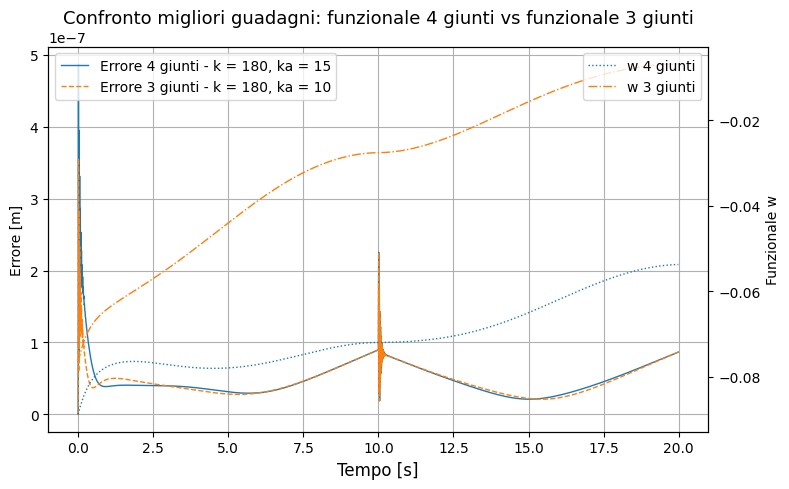

In [4]:
# Visualizzazione dei risultati migliori per i due funzionali
fig, ax1 = plt.subplots(figsize=(8, 5))
ax1.set_title("Confronto migliori guadagni: funzionale 4 giunti vs funzionale 3 giunti", fontsize=13)
ax1.set_xlabel('Tempo [s]', fontsize=12)

# Errore di tracking
ax1.plot(time, best[4].flatten(), linewidth=1, label=f'Errore 4 giunti - k = {best[0]}, ka = {best[1]}')
ax1.plot(time, best_3[4].flatten(), linewidth=1, linestyle='--', label=f'Errore 3 giunti - k = {best_3[0]}, ka = {best_3[1]}')
ax1.set_ylabel('Errore [m]')
ax1.grid(True)
ax1.legend(loc='upper left')

# Funzionale w
ax2 = ax1.twinx()
ax2.plot(time, best[5].flatten(), linewidth=1, linestyle=':', label='w 4 giunti')
ax2.plot(time, best_3[5].flatten(), linewidth=1, linestyle='-.', label='w 3 giunti')
ax2.set_ylabel('Funzionale w')
ax2.legend(loc='upper right')

fig.tight_layout()
plt.show()